# training_dataset_id analysis

In [ ]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import json

# Add the project root to sys.path so that 'src' can be imported
project_root = Path.cwd().parents[2]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.constants import get_full_path

## Helper functions

In [2]:
def summarize_dataset(df, cat2color):

    cell_type_cols = list(cat2color.keys())

    # Define a dictionary to store results
    results = {}

    # Remove in df row that belong to the set "att" and print number of removed rows
    print(f"Removing {df[df['set'] == 'att'].shape[0]} rows belonging to the 'att' set, over {df.shape[0]} total rows.")
    df = df[df['set'] != 'att']

    # Iterate through each set and calculate the stats
    for set_name in df['set'].unique().tolist() + ['Total']:
        # Subset for each set or whole dataset
        subset = df if set_name == 'Total' else df[df['set'] == set_name]

        # Calculate stats
        total_patches = subset['patch_id'].nunique()
        cell_counts = subset[cell_type_cols].sum()
        total_cells = cell_counts.sum()
        patch_counts_per_type = subset.groupby('patch_id')[cell_type_cols].sum().apply(lambda x: x > 0).sum()

        # Calculate percentages per cell type
        percentages = (cell_counts / total_cells * 100).round(2)

        # Store results in the dictionary
        results[set_name] = {
            'Total Patches': total_patches,
            'Total Cells': total_cells,
            **{f"{cell} Count": cell_counts[cell] for cell in cell_type_cols},
            **{f"{cell} Patch Count": patch_counts_per_type[cell] for cell in cell_type_cols},
            **{f"{cell} (%)": percentages[cell] for cell in cell_type_cols}
        }

    # Create a DataFrame for display
    summary_df = pd.DataFrame(results).T

    # Organize columns for better readability
    ordered_columns = (
        ['Total Patches', 'Total Cells'] +
        [f"{cell} Count" for cell in cell_type_cols] +
        [f"{cell} Patch Count" for cell in cell_type_cols] +
        [f"{cell} (%)" for cell in cell_type_cols]
    )
    summary_df = summary_df[ordered_columns]

    # Order the rows (train, valid, test, total)
    summary_df = summary_df.loc[['train', 'valid', 'test', 'Total']]

    # Function to format the numbers
    def format_columns(col):
        # Apply formatting based on the column name
        return col.apply(lambda x: f"{x:,.1f}" if isinstance(x, (int, float)) and "(%)" in col.name else f"{x:,.0f}" if isinstance(x, (int, float)) else x)


    # Format the numbers in the DataFrame
    styled_summary_df = summary_df.apply(format_columns)

    # Function to apply colors to specific column groups
    def highlight_columns(col):
        if col.name in ['Total Patches', 'Total Cells']:
            return ['background-color: lightblue'] * len(col)
        elif "Count" in col.name and "Patch" not in col.name:
            return ['background-color: lightgreen'] * len(col)
        elif "Patch Count" in col.name:
            return ['background-color: lightcoral'] * len(col)
        elif "(%)" in col.name:
            return ['background-color: lightyellow'] * len(col)
        else:
            return [''] * len(col)

    # Apply the highlighting to each column (not row-wise)
    styled_summary_df = styled_summary_df.style.apply(highlight_columns, axis=0)

    # Display the summary table
    display(styled_summary_df)

    # Do not hide columns for better visibility
    pd.set_option('display.max_columns', 100)

    return summary_df

In [3]:
def plot_dataset(df, group_col, cat2color, type_col, set):

    # Extract cell type columns and colors
    cell_type_cols = list(cat2color.keys())
    cell_type_colors = {k: [c / 255 for c in v] for k, v in cat2color.items()}  # Normalize RGB to 0-1

    # Subset the data based on the set
    if set == "train":
        df_plot = df[df["set"] == "train"].copy()
    elif set == "valid":
        df_plot = df[df["set"] == "valid"].copy()
    elif set == "test":
        df_plot = df[df["set"] == "test"].copy()
    else:
        df_plot = df.copy()
    
    # Removing rows that belong to the 'att' set if any
    print(f"Removing {df_plot[df_plot['set'] == 'att'].shape[0]} rows belonging to the 'att' set, over {df_plot.shape[0]} total rows.")
    df_plot = df_plot[df_plot['set'] != 'att']

    # Handle if group_col = type_col
    if group_col == type_col:
        group_col = group_col + "_"
        df_plot[group_col] = df_plot[type_col]

    # Aggregate cell counts by group_col and cell type
    slide_totals = df_plot.groupby([group_col, type_col])[cell_type_cols].sum().reset_index()
    slide_totals["Total"] = slide_totals[cell_type_cols].sum(axis=1)
    
    # Sort by slide ID in alphabetical order
    slide_totals = slide_totals.sort_values(by=group_col, ascending=True)

    # Set up the plot
    fig, ax = plt.subplots(figsize=(10, 8))

    # Plot the stacked bar chart
    bottom = None
    for cell_type in cell_type_cols:
        ax.barh(
            slide_totals[group_col],
            slide_totals[cell_type],
            left=bottom,
            color=cell_type_colors[cell_type],  # Custom colors for cell types
            label=f"{cell_type} ({slide_totals[cell_type].sum():,.0f})"
        )
        bottom = slide_totals[cell_type] if bottom is None else bottom + slide_totals[cell_type]

    # Customize x-axis and slide labels
    ax.set_xlabel("cell count")
    ax.set_ylabel(group_col)
    ax.set_title(f"Set: {set}")
    ax.invert_yaxis()

    # Generate a color map for the 'type' column
    unique_types = slide_totals[type_col].unique()
    type_colors = dict(zip(unique_types, sns.color_palette("Dark2", len(unique_types))))

    # Color slide labels according to the 'type' column
    slide_labels = [f"{slide} ({total:,.0f})" for slide, total in zip(slide_totals[group_col], slide_totals["Total"])]
    slide_colors = slide_totals[type_col].map(type_colors)

    ax.set_yticks(range(len(slide_totals)))
    ax.set_yticklabels(slide_labels, ha='right', fontsize=10)

    for label, color in zip(ax.get_yticklabels(), slide_colors):
        label.set_color(color)

    # Adjust legend appearance for cell type
    custom_legend = [Patch(facecolor=cell_type_colors[cell_type], edgecolor="black", label=f"{cell_type} ({slide_totals[cell_type].sum():,.0f})")
                     for cell_type in cell_type_cols]
    ax.legend(handles=custom_legend, title="Cell Type", loc="upper center", bbox_to_anchor=(0.5, -0.12),
              ncol=3, frameon=True, framealpha=1, facecolor='none', edgecolor='black', fontsize=10, title_fontsize=12)

    plt.tight_layout()
    plt.show()

In [4]:
def plot_all_metrics(df_metrics):

    metrics = ['Dice', 'Jaccard', 'bPQ']

    plt.figure(figsize=(9, 3))

    for i, metric in enumerate(metrics, 1):
        plt.subplot(1, 3, i)
        sns.histplot(df_metrics[metric], bins=30, kde=True, color='blue')
        plt.title(f'{metric}')
        plt.xlabel(metric)
        plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

## ds_ct1_20x_224_o112_1

In [5]:
dataset_id = 'ds_ct1_20x_224_o112'
training_dataset_id = 'ds_ct1_20x_224_o112_1'
cell_cat_id = 'ct_1'

In [14]:
infos_path = get_full_path('train', 'training_datasets', dataset_id, training_dataset_id, 'informations', f'infos_{training_dataset_id}.csv', as_str=True)
df = pd.read_csv(infos_path)
df.head()

,patch_id,T_NK,B_Plasma,Myeloid,Blood_vessel,Fibroblast_Myofibroblast,Epithelial,Specialized,Melanocyte,Unknown,type,slide_id,x_min,y_min,x_max,y_max,set
0,breast_s0_62,0,0,0,1,0,0,0,0,0,Breast,breast_s0,6944,0,7168,224,train
1,breast_s0_63,0,0,0,1,0,0,0,0,0,Breast,breast_s0,7056,0,7280,224,train
2,breast_s0_265,1,0,0,0,0,1,0,0,0,Breast,breast_s0,5488,112,5712,336,train
3,breast_s0_266,3,1,1,0,0,1,0,0,0,Breast,breast_s0,5600,112,5824,336,train
4,breast_s0_267,3,1,1,0,0,0,0,0,0,Breast,breast_s0,5712,112,5936,336,train


In [7]:
df.isna().sum().sum()

np.int64(0)

In [8]:
#plot_all_metrics(df)  # no segmentation metrics available for this dataset

In [9]:
with open(f"/path/to/ALHENA-paper/data/annots/annot_dicts_{cell_cat_id}/cat2color.json", "r") as f:
    cat2color = json.load(f)
cat2color

{'T_NK': [255, 15, 15],
 'B_Plasma': [255, 143, 15],
 'Myeloid': [255, 211, 15],
 'Blood_vessel': [70, 128, 0],
 'Fibroblast_Myofibroblast': [156, 255, 36],
 'Epithelial': [57, 208, 133],
 'Specialized': [69, 237, 255],
 'Melanocyte': [22, 169, 223],
 'Unknown': [143, 143, 143]}

In [10]:
summary_df = summarize_dataset(df, cat2color)

Removing 8425 rows belonging to the 'att' set, over 467888 total rows.


,Total Patches,Total Cells,T_NK Count,B_Plasma Count,Myeloid Count,Blood_vessel Count,Fibroblast_Myofibroblast Count,Epithelial Count,Specialized Count,Melanocyte Count,Unknown Count,T_NK Patch Count,B_Plasma Patch Count,Myeloid Patch Count,Blood_vessel Patch Count,Fibroblast_Myofibroblast Patch Count,Epithelial Patch Count,Specialized Patch Count,Melanocyte Patch Count,Unknown Patch Count,T_NK (%),B_Plasma (%),Myeloid (%),Blood_vessel (%),Fibroblast_Myofibroblast (%),Epithelial (%),Specialized (%),Melanocyte (%),Unknown (%)
train,"340,263","35,193,515","5,401,948","3,608,950","4,525,213","2,809,147","5,117,312","10,377,476","103,381","538,523","2,711,565","218,151","92,034","300,915","232,166","286,905","226,485","10,923","12,070","180,867",15.3,10.2,12.9,8.0,14.5,29.5,0.3,1.5,7.7
valid,"65,094","5,280,855","598,615","343,342","639,386","399,904","584,102","2,316,392","55,889","51,510","291,715","46,141","21,865","57,221","45,776","55,042","49,642","16,483","1,009","23,243",11.3,6.5,12.1,7.6,11.1,43.9,1.1,1.0,5.5
test,"54,106","4,850,968","546,661","322,345","566,134","452,786","604,186","1,833,429","3,439","52,532","469,456","37,806","16,379","47,736","38,329","43,239","39,072",406,"1,245","32,960",11.3,6.6,11.7,9.3,12.4,37.8,0.1,1.1,9.7
Total,"459,463","45,325,338","6,547,224","4,274,637","5,730,733","3,661,837","6,305,600","14,527,297","162,709","642,565","3,472,736","302,098","130,278","405,872","316,271","385,186","315,199","27,812","14,324","237,070",14.4,9.4,12.6,8.1,13.9,32.0,0.4,1.4,7.7


Removing 8425 rows belonging to the 'att' set, over 467888 total rows.


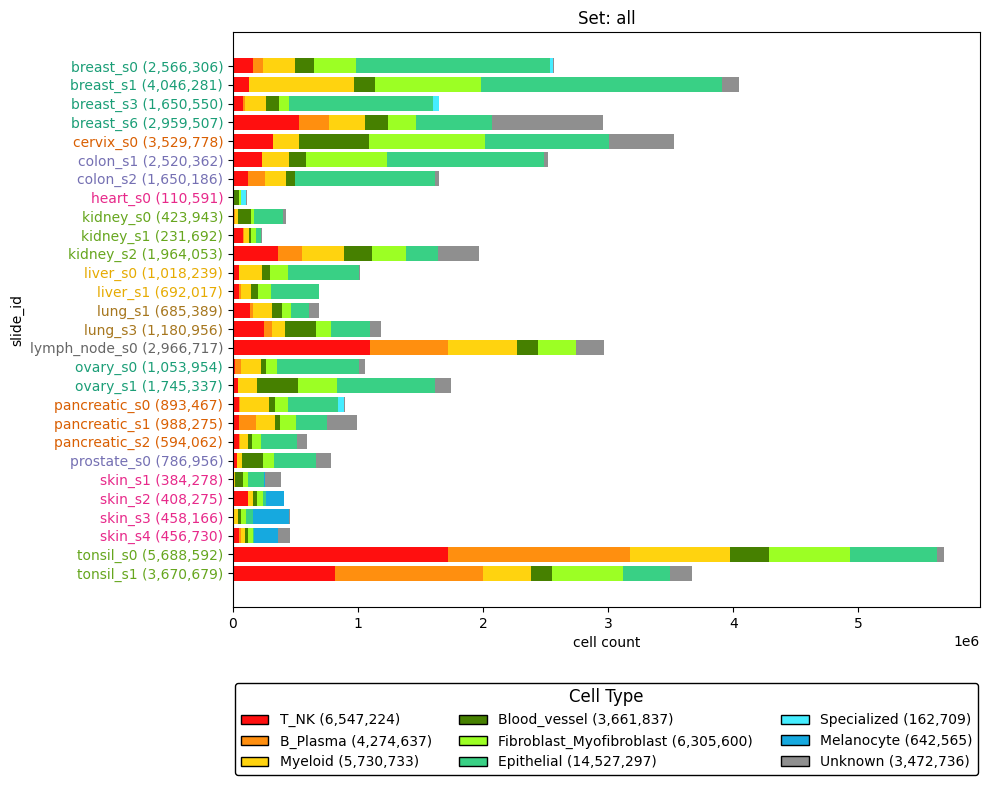

In [11]:
plot_dataset(df, 'slide_id', cat2color, 'type', 'all')

Removing 8425 rows belonging to the 'att' set, over 467888 total rows.


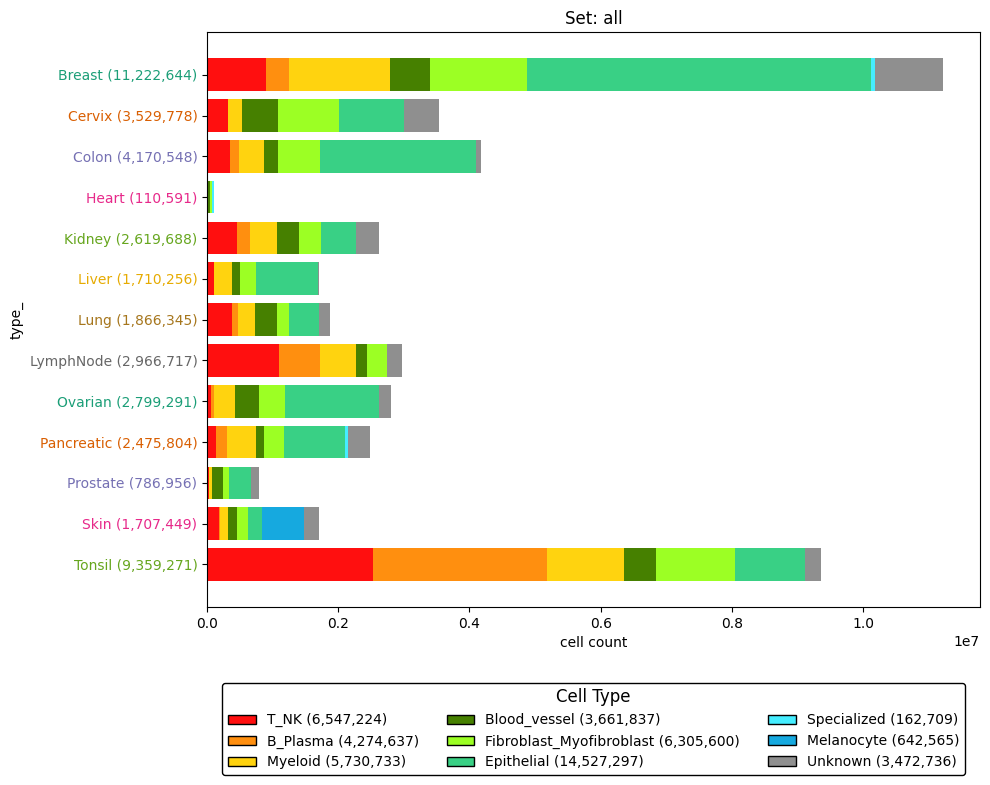

In [12]:
plot_dataset(df, 'type', cat2color, 'type', 'all')

In [13]:
print("COUNT OF PATCHES IN TRAIN SET FOR EACH TISSUE TYPE (ALPHABETICAL ORDER):")
df[df['set'] == 'train']['type'].value_counts().sort_index()

COUNT OF PATCHES IN TRAIN SET FOR EACH TISSUE TYPE (ALPHABETICAL ORDER):


type
Breast        126617
Cervix         21218
Colon          19898
Heart           3418
Kidney         16020
Liver          18368
Lung           18918
LymphNode       9599
Ovarian        22763
Pancreatic     22614
Prostate        8722
Skin           23324
Tonsil         28784
Name: count, dtype: int64

### after filtering by n_min_cells per patches == 5

In [6]:
infos_path_min5 = get_full_path('train', 'training_datasets', dataset_id, training_dataset_id, 'informations_5', f'infos_{training_dataset_id}_5.csv', as_str=True)
df_min5 = pd.read_csv(infos_path_min5)
df_min5.head()

,patch_id,T_NK,B_Plasma,Myeloid,Blood_vessel,Fibroblast_Myofibroblast,Epithelial,Specialized,Melanocyte,Unknown,type,slide_id,x_min,y_min,x_max,y_max,set
0,breast_s0_266,3,1,1,0,0,1,0,0,0,Breast,breast_s0,5600,112,5824,336,train
1,breast_s0_267,3,1,1,0,0,0,0,0,0,Breast,breast_s0,5712,112,5936,336,train
2,breast_s0_277,0,1,0,0,0,3,4,0,0,Breast,breast_s0,6832,112,7056,336,train
3,breast_s0_278,0,1,0,1,0,3,1,0,0,Breast,breast_s0,6944,112,7168,336,train
4,breast_s0_281,1,1,0,0,0,3,0,0,0,Breast,breast_s0,7280,112,7504,336,train


In [7]:
df_min5.isna().sum().sum()

np.int64(0)

In [ ]:
#plot_all_metrics(df_min5)  # no segmentation metrics available for this dataset

In [8]:
with open(f"/path/to/ALHENA-paper/data/annots/annot_dicts_{cell_cat_id}/cat2color.json", "r") as f:
    cat2color = json.load(f)
cat2color

{'T_NK': [255, 15, 15],
 'B_Plasma': [255, 143, 15],
 'Myeloid': [255, 211, 15],
 'Blood_vessel': [70, 128, 0],
 'Fibroblast_Myofibroblast': [156, 255, 36],
 'Epithelial': [57, 208, 133],
 'Specialized': [69, 237, 255],
 'Melanocyte': [22, 169, 223],
 'Unknown': [143, 143, 143]}

In [9]:
summary_df_min5 = summarize_dataset(df_min5, cat2color)

Removing 0 rows belonging to the 'att' set, over 440270 total rows.


,Total Patches,Total Cells,T_NK Count,B_Plasma Count,Myeloid Count,Blood_vessel Count,Fibroblast_Myofibroblast Count,Epithelial Count,Specialized Count,Melanocyte Count,Unknown Count,T_NK Patch Count,B_Plasma Patch Count,Myeloid Patch Count,Blood_vessel Patch Count,Fibroblast_Myofibroblast Patch Count,Epithelial Patch Count,Specialized Patch Count,Melanocyte Patch Count,Unknown Patch Count,T_NK (%),B_Plasma (%),Myeloid (%),Blood_vessel (%),Fibroblast_Myofibroblast (%),Epithelial (%),Specialized (%),Melanocyte (%),Unknown (%)
train,"327,955","35,165,547","5,400,690","3,608,438","4,520,139","2,807,079","5,110,766","10,373,806","103,172","538,364","2,703,093","217,096","91,612","297,599","230,758","282,826","224,131","10,807","11,965","175,840",15.4,10.3,12.8,8.0,14.5,29.5,0.3,1.5,7.7
valid,"60,996","5,270,929","597,954","343,184","638,054","399,148","580,049","2,314,991","55,113","51,508","290,928","45,565","21,727","56,182","45,240","52,638","48,608","16,016","1,007","22,724",11.3,6.5,12.1,7.6,11.0,43.9,1.1,1.0,5.5
test,"51,319","4,845,030","546,385","322,286","564,920","452,240","602,472","1,832,523","3,412","52,512","468,280","37,560","16,321","46,907","37,944","42,198","38,522",389,"1,235","32,083",11.3,6.7,11.7,9.3,12.4,37.8,0.1,1.1,9.7
Total,"440,270","45,281,506","6,545,029","4,273,908","5,723,113","3,658,467","6,293,287","14,521,320","161,697","642,384","3,462,301","300,221","129,660","400,688","313,942","377,662","311,261","27,212","14,207","230,647",14.4,9.4,12.6,8.1,13.9,32.1,0.4,1.4,7.7


Removing 0 rows belonging to the 'att' set, over 440270 total rows.


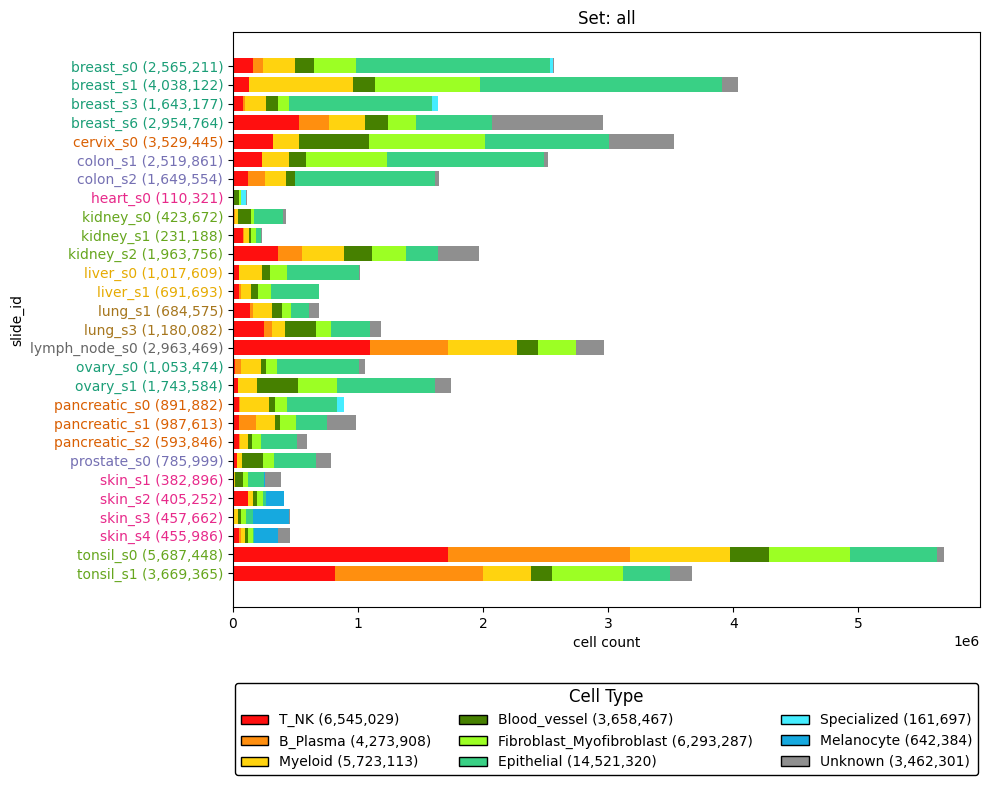

In [10]:
plot_dataset(df_min5, 'slide_id', cat2color, 'type', 'all')

Removing 0 rows belonging to the 'att' set, over 440270 total rows.


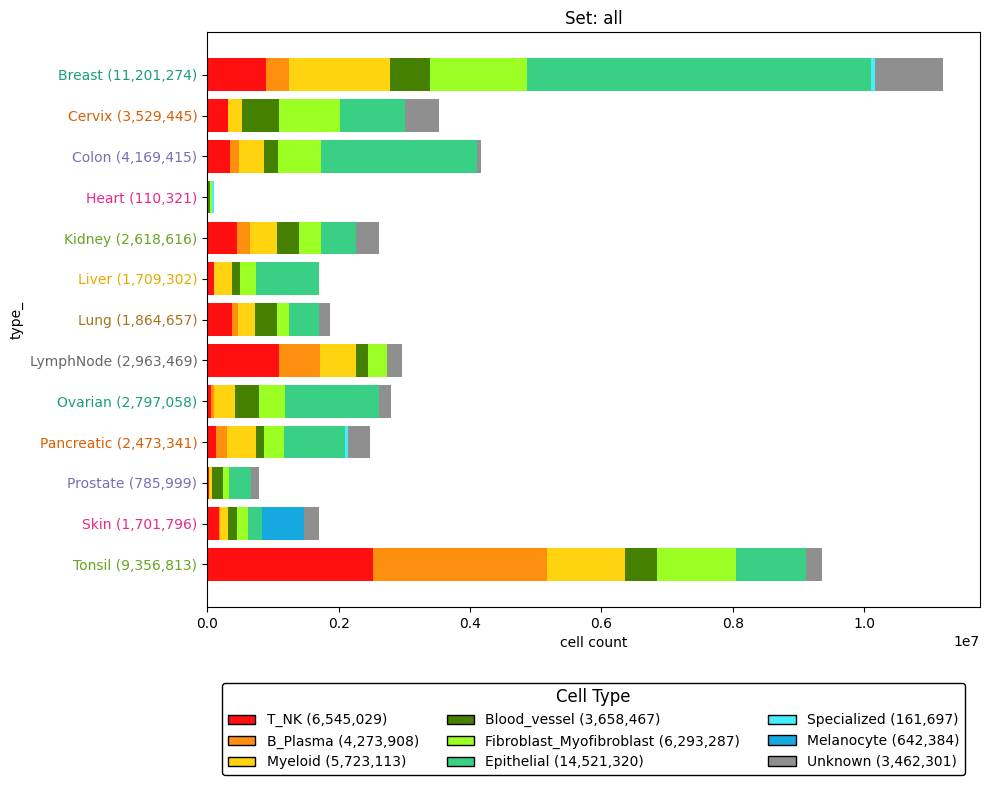

In [11]:
plot_dataset(df_min5, 'type', cat2color, 'type', 'all')

In [12]:
print("COUNT OF PATCHES IN TRAIN SET FOR EACH TISSUE TYPE (ALPHABETICAL ORDER):")
df_min5[df_min5['set'] == 'train']['type'].value_counts().sort_index()

COUNT OF PATCHES IN TRAIN SET FOR EACH TISSUE TYPE (ALPHABETICAL ORDER):


type
Breast        121790
Cervix         21091
Colon          19435
Heart           3343
Kidney         15765
Liver          18030
Lung           18243
LymphNode       8789
Ovarian        22017
Pancreatic     22157
Prostate        8225
Skin           21298
Tonsil         27772
Name: count, dtype: int64

In [15]:
# Count number of patches with less than 5 cells
print(f"Number of patches with less than 5 cells: {len(df) - len(df_min5)}")

Number of patches with less than 5 cells: 27618


In [16]:
# Count of patches with less than 5 cells per slide_id
patches_less_5_cells = df[~df['patch_id'].isin(df_min5['patch_id'])]
count_less_5_cells_per_slide = patches_less_5_cells.groupby('slide_id')['patch_id'].nunique()
print("Count of patches with less than 5 cells per slide_id:")
print(count_less_5_cells_per_slide.sort_index())

Count of patches with less than 5 cells per slide_id:
slide_id
breast_s0        1156
breast_s1        3870
breast_s3        2904
breast_s6        2533
cervix_s0         848
colon_s1          590
colon_s2          494
heart_s0          296
kidney_s0         141
kidney_s1         380
kidney_s2         501
liver_s0          728
liver_s1          383
lung_s1           613
lung_s3           876
lymph_node_s0    1704
ovary_s0          435
ovary_s1         1206
pancreatic_s0     979
pancreatic_s1     621
pancreatic_s2      90
prostate_s0       753
skin_s1           737
skin_s2          1644
skin_s3           404
skin_s4           654
tonsil_s0        1068
tonsil_s1        1010
Name: patch_id, dtype: int64


In [17]:
# Count of patches with less than 5 cells per set
for set_name in df['set'].unique():
    count_less_5_cells_per_set = patches_less_5_cells[patches_less_5_cells['set'] == set_name]['patch_id'].nunique()
    print(f"Count of patches with less than 5 cells in set '{set_name}': {count_less_5_cells_per_set}")

Count of patches with less than 5 cells in set 'train': 12308
Count of patches with less than 5 cells in set 'att': 8425
Count of patches with less than 5 cells in set 'valid': 4098
Count of patches with less than 5 cells in set 'test': 2787
